In [3]:
# @title Upload 4 Berkas Excel Baru (1 Pembobot + 3 Bidang Dataset)
from google.colab import files
import os

print("Silakan unggah 4 file Excel Anda:")
print("1. Berkas Pembobot (W8)")
print("2. Berkas Dataset TPT")
print("3. Berkas Dataset Kesehatan")
print("4. Berkas Dataset Pendidikan")
uploaded_files = files.upload()

# Menampilkan daftar berkas yang berhasil diunggah
print("\nBerkas yang berhasil diunggah:")
for filename in uploaded_files.keys():
    print(f"- {filename} ({len(uploaded_files[filename])} bytes)")

Silakan unggah 4 file Excel Anda:
1. Berkas Pembobot (W8)
2. Berkas Dataset TPT
3. Berkas Dataset Kesehatan
4. Berkas Dataset Pendidikan


Saving W8_JarakCentroid_10th_PlusInverseKuantilPlasebo_ok.xlsx to W8_JarakCentroid_10th_PlusInverseKuantilPlasebo_ok.xlsx
Saving data_JarakCentroid_10th_Pendidikan.xlsx to data_JarakCentroid_10th_Pendidikan (1).xlsx
Saving data_JarakCentroid_10th_Kesehatan.xlsx to data_JarakCentroid_10th_Kesehatan (1).xlsx
Saving data_JarakCentroid_10th_TPT.xlsx to data_JarakCentroid_10th_TPT (1).xlsx

Berkas yang berhasil diunggah:
- W8_JarakCentroid_10th_PlusInverseKuantilPlasebo_ok.xlsx (4603673 bytes)
- data_JarakCentroid_10th_Pendidikan (1).xlsx (19182 bytes)
- data_JarakCentroid_10th_Kesehatan (1).xlsx (20352 bytes)
- data_JarakCentroid_10th_TPT (1).xlsx (20352 bytes)


### Konfigurasi Nama File dan Analisis Multi-Dataset
Setelah mengunggah berkas-berkas di atas, silakan sesuaikan nama file pada sel di bawah ini sesuai dengan nama file yang Anda unggah, lalu jalankan untuk mengevaluasi seluruh pembobot spasial-temporal terhadap 4 bidang tersebut secara simultan.

In [4]:
# @title Pemrosesan 3 Bidang Dataset Lintas Seluruh Pembobot (Periode 10 Tahun)
import pandas as pd
import numpy as np
import os
from google.colab import files

# ==========================================
# KONFIGURASI FILE BARU 10 TAHUN
# ==========================================
W8_FILE_PATH = "W8_JarakCentroid_10th_PlusInverseKuantilPlasebo_ok.xlsx"  # File pembobot 10 tahun

# Hanya 3 bidang (tanpa Pertanian) untuk periode 10 tahun
datasets_config = {
    "TPT": "data_JarakCentroid_10th_TPT.xlsx",
    "Kesehatan": "data_JarakCentroid_10th_Kesehatan.xlsx",
    "Pendidikan": "data_JarakCentroid_10th_Pendidikan.xlsx"
}

def fit_eq13_fixed_effect(df_in, Wy):
    """
    Fit: y_it = rho*Wy_it + beta*y_{i,t-1} + mu_i + eps_it
    using within transformation (demean by location).
    """
    dfm = df_in.copy()
    dfm["Wy"] = Wy

    # gunakan hanya baris dengan lag tersedia
    dfm = dfm.dropna(subset=["Y_(t-1)"]).copy()

    y = dfm["Y"].astype(float).to_numpy()
    x1 = dfm["Wy"].astype(float).to_numpy()
    x2 = dfm["Y_(t-1)"].astype(float).to_numpy()
    g  = dfm["loc_id"].to_numpy()

    # within (demean by group)
    y_dm  = y  - pd.Series(y).groupby(g).transform("mean").to_numpy()
    x1_dm = x1 - pd.Series(x1).groupby(g).transform("mean").to_numpy()
    x2_dm = x2 - pd.Series(x2).groupby(g).transform("mean").to_numpy()

    X = np.column_stack([x1_dm, x2_dm])

    # OLS
    XtX = X.T @ X
    Xty = X.T @ y_dm
    coef = np.linalg.solve(XtX, Xty)

    rho_hat, beta_hat = coef[0], coef[1]

    # fitted untuk versi demeaned
    yhat_dm = X @ coef
    resid_dm = y_dm - yhat_dm

    # RMSE dan R2 (within)
    rmse = float(np.sqrt(np.mean(resid_dm**2)))
    ss_res = float(np.sum(resid_dm**2))
    ss_tot = float(np.sum((y_dm - y_dm.mean())**2))
    r2 = 1.0 - ss_res/ss_tot if ss_tot > 0 else np.nan

    return {
        "rho_hat": float(rho_hat),
        "beta_hat": float(beta_hat),
        "rmse_within": rmse,
        "r2_within": r2,
        "n_obs": int(len(dfm))
    }

def compute_Wy_bd_dynamic(df, W_bd):
    """
    W_bd: 35x35, dihitung per tahun secara fleksibel untuk total baris berapapun
    """
    Wy = np.zeros(len(df), dtype=float)
    for yr in sorted(df["Waktu"].unique()):
        idx = df.index[df["Waktu"] == yr].to_numpy()
        y_t = df.loc[idx, "Y"].astype(float).to_numpy().reshape(-1,1)
        if y_t.shape[0] != W_bd.shape[0]:
            raise ValueError(f"Year {yr}: expected {W_bd.shape[0]} rows, got {y_t.shape[0]}")
        Wy[idx] = (W_bd @ y_t).ravel()
    return Wy

# List Lembar Pembobot W_ST dan W_bd
W_ST_sheets = [
    "W_ST^Q", "W_ST^Q10", "W_ST^Qq", "W_ST^Q10q",
    "W_ST^Qr", "W_ST^Q10r", "W_ST^iq", "W_bdst", "Wseragam_diag0",
    "Wseragam_diag1", "Wacak_diag0", "Wacak_diag1"
]
W_bd_sheet = "W_bd"

all_results = []

try:
    print("Membaca matriks pembobot dasar dari file Excel...")
    loaded_W_ST_base = {}
    for sh in W_ST_sheets:
        loaded_W_ST_base[sh] = pd.read_excel(W8_FILE_PATH, sheet_name=sh, header=None).to_numpy(dtype=float)
    W_bd = pd.read_excel(W8_FILE_PATH, sheet_name=W_bd_sheet, header=None).to_numpy(dtype=float)

    # Memproses setiap bidang dataset (3 bidang, 10 tahun)
    for nama_bidang, file_path in datasets_config.items():
        if not os.path.exists(file_path):
            print(f"[Peringatan] Berkas untuk bidang '{nama_bidang}' ({file_path}) tidak ditemukan.")
            continue

        print(f"Memproses Bidang: {nama_bidang} ({file_path})...")
        df_bidang = pd.read_excel(file_path)

        # Buat ID lokasi
        loc_order = df_bidang["Lokasi"].drop_duplicates().tolist()
        loc_to_id = {name: i for i, name in enumerate(loc_order)}
        df_bidang["loc_id"] = df_bidang["Lokasi"].map(loc_to_id)

        n_loc = df_bidang["loc_id"].nunique()
        t_years = df_bidang["Waktu"].nunique()
        n_total = len(df_bidang)
        print(f"-> Terdeteksi {n_loc} lokasi x {t_years} tahun = {n_total} baris data.")

        # 1. Jalankan untuk 13 Matriks W_ST (Disesuaikan skalanya ke 10 tahun secara dinamis)
        for sh in W_ST_sheets:
            W_base = loaded_W_ST_base[sh]
            # Memotong ke struktur spasial dasar 35x35 dan mengekspansi menggunakan Kronecker Product sesuai jumlah tahun (10 tahun)
            W_s_base = W_base[:35, :35]
            W_ST_expanded = np.kron(np.eye(t_years), W_s_base)

            Wy = (W_ST_expanded @ df_bidang["Y"].astype(float).to_numpy().reshape(-1, 1)).ravel()
            res = fit_eq13_fixed_effect(df_bidang, Wy)
            res.update({
                "Bidang": nama_bidang,
                "Pembobot": sh,
                "Wy_type": f"W_ST ({n_total}x{n_total})"
            })
            all_results.append(res)

        # 2. Jalankan untuk Matriks W_bd
        Wy_bd = compute_Wy_bd_dynamic(df_bidang, W_bd)
        res_bd = fit_eq13_fixed_effect(df_bidang, Wy_bd)
        res_bd.update({
            "Bidang": nama_bidang,
            "Pembobot": "W_bd",
            "Wy_type": f"W_bd per-year ({n_loc}x{n_loc})"
        })
        all_results.append(res_bd)

    # Gabungkan semua hasil dan tampilkan
    if all_results:
        grand_res_df = pd.DataFrame(all_results)
        cols = ["Bidang", "Pembobot", "Wy_type", "rho_hat", "beta_hat", "r2_within", "rmse_within", "n_obs"]
        grand_res_df = grand_res_df[cols].sort_values(["Bidang", "Pembobot"]).reset_index(drop=True)
        display(grand_res_df)

        # Simpan hasil kompilasi ke Excel
        output_all_fields = "Hasil_Simulasi_Gabungan_3_Bidang_10th.xlsx"
        grand_res_df.to_excel(output_all_fields, index=False)
        print(f"\nHasil kompilasi sukses disimpan ke '{output_all_fields}'!")
        files.download(output_all_fields)
    else:
        print("Tidak ada data yang diproses.")
except Exception as e:
    print(f"Terjadi kesalahan saat memproses data: {e}")

Membaca matriks pembobot dasar dari file Excel...
Memproses Bidang: TPT (data_JarakCentroid_10th_TPT.xlsx)...
-> Terdeteksi 35 lokasi x 10 tahun = 350 baris data.
Memproses Bidang: Kesehatan (data_JarakCentroid_10th_Kesehatan.xlsx)...
-> Terdeteksi 35 lokasi x 10 tahun = 350 baris data.
Memproses Bidang: Pendidikan (data_JarakCentroid_10th_Pendidikan.xlsx)...
-> Terdeteksi 35 lokasi x 10 tahun = 350 baris data.


,Bidang,Pembobot,Wy_type,rho_hat,beta_hat,r2_within,rmse_within,n_obs
0,Kesehatan,W_ST^Q,W_ST (350x350),0.695794,0.084439,0.887697,1.931415,315
1,Kesehatan,W_ST^Q10,W_ST (350x350),0.691691,0.087312,0.883440,1.967687,315
2,Kesehatan,W_ST^Q10q,W_ST (350x350),0.615950,0.119232,0.826824,2.398412,315
3,Kesehatan,W_ST^Q10r,W_ST (350x350),0.639480,0.115999,0.833232,2.353619,315
4,Kesehatan,W_ST^Qq,W_ST (350x350),0.615361,0.120978,0.825569,2.407090,315
5,Kesehatan,W_ST^Qr,W_ST (350x350),0.619195,0.128599,0.823070,2.424268,315
6,Kesehatan,W_ST^iq,W_ST (350x350),0.937009,0.213774,0.276156,4.903461,315
7,Kesehatan,W_bd,W_bd per-year (35x35),0.848492,0.222935,0.250588,4.989313,315
8,Kesehatan,W_bdst,W_ST (350x350),0.684285,0.097253,0.872004,2.061956,315
9,Kesehatan,Wacak_diag0,W_ST (350x350),0.055561,0.205010,0.273231,4.913358,315



Hasil kompilasi sukses disimpan ke 'Hasil_Simulasi_Gabungan_3_Bidang_10th.xlsx'!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
#2) Wy building function for W_ST (350×350) and W_bd (35×35)

def compute_Wy_ST(df, W_ST):
    """
    W_ST: 350x350, dikalikan langsung dengan vektor y (panjang 350)
    sesuai urutan baris df.
    """
    y_vec = df["Y"].astype(float).to_numpy().reshape(-1,1)  # 350x1
    Wy = (W_ST @ y_vec).ravel()
    return Wy

def compute_Wy_bd(df, W_bd):
    """
    W_bd: 35x35, dihitung per tahun:
    Wy_t = W_bd @ y_t, lalu distack sesuai urutan df.
    Asumsi: dalam setiap tahun, urutan 35 lokasi di df sama dengan urutan W_bd.
    """
    Wy = np.zeros(len(df), dtype=float)
    for yr in df["Waktu"].unique():
        idx = df.index[df["Waktu"] == yr].to_numpy()
        y_t = df.loc[idx, "Y"].astype(float).to_numpy().reshape(-1,1)  # 35x1
        if y_t.shape[0] != W_bd.shape[0]:
            raise ValueError(f"Year {yr}: expected {W_bd.shape[0]} rows, got {y_t.shape[0]}")
        Wy[idx] = (W_bd @ y_t).ravel()
    return Wy


In [6]:
#3) estimation with location fixed effect (within estimator)

def fit_eq31_fixed_effect(df_in, Wy):
    """
    Fit: y_it = rho*Wy_it + beta*y_{i,t-1} + mu_i + eps_it
    using within transformation (demean by location).

    Returns: rho_hat, beta_hat, fitted, residual, R2, RMSE, n_obs
    """
    dfm = df_in.copy()
    dfm["Wy"] = Wy

    # gunakan hanya baris dengan lag tersedia (2019–2022)
    dfm = dfm.dropna(subset=["Y_(t-1)"]).copy()

    y = dfm["Y"].astype(float).to_numpy()
    x1 = dfm["Wy"].astype(float).to_numpy()
    x2 = dfm["Y_(t-1)"].astype(float).to_numpy()
    g  = dfm["loc_id"].to_numpy()

    # within (demean by group)
    y_dm  = y  - pd.Series(y).groupby(g).transform("mean").to_numpy()
    x1_dm = x1 - pd.Series(x1).groupby(g).transform("mean").to_numpy()
    x2_dm = x2 - pd.Series(x2).groupby(g).transform("mean").to_numpy()

    X = np.column_stack([x1_dm, x2_dm])  # tanpa intercept (FE sudah dihapus via demeaning)

    # OLS
    XtX = X.T @ X
    Xty = X.T @ y_dm
    coef = np.linalg.solve(XtX, Xty)

    rho_hat, beta_hat = coef[0], coef[1]

    # fitted untuk versi demeaned
    yhat_dm = X @ coef
    resid_dm = y_dm - yhat_dm

    # RMSE dan R2 (within)
    rmse = float(np.sqrt(np.mean(resid_dm**2)))
    ss_res = float(np.sum(resid_dm**2))
    ss_tot = float(np.sum((y_dm - y_dm.mean())**2))
    r2 = 1.0 - ss_res/ss_tot if ss_tot > 0 else np.nan

    return {
        "rho_hat": float(rho_hat),
        "beta_hat": float(beta_hat),
        "rmse_within": rmse,
        "r2_within": r2,
        "n_obs": int(len(dfm))
    }


In [7]:
#4) Run for all weights across all 3 dataset fields

import pandas as pd
import numpy as np

W8_PATH = "W8_JarakCentroid_10th_PlusInverseKuantilPlasebo_ok.xlsx"

# Konfigurasi berkas untuk masing-masing bidang
datasets_config = {
    "TPT": "data_JarakCentroid_10th_TPT.xlsx",
    "Kesehatan": "data_JarakCentroid_10th_Kesehatan.xlsx",
    "Pendidikan": "data_JarakCentroid_10th_Pendidikan.xlsx",
}

xls = pd.ExcelFile(W8_PATH)
print("Sheets yang ditemukan di file pembobot:", xls.sheet_names)

W_ST_sheets = ["W_ST^Q","W_ST^Q10","W_ST^Qq","W_ST^Q10q","W_ST^Qr","W_ST^Q10r","W_ST^iq","W_bdst","Wseragam_diag0","Wseragam_diag1","Wacak_diag0","Wacak_diag1"]
W_bd_sheet  = "W_bd"

# Membaca seluruh matriks pembobot terlebih dahulu
loaded_W_ST = {}
for sh in W_ST_sheets:
    loaded_W_ST[sh] = pd.read_excel(W8_PATH, sheet_name=sh, header=None).to_numpy(dtype=float)
W_bd = pd.read_excel(W8_PATH, sheet_name=W_bd_sheet, header=None).to_numpy(dtype=float)

all_results = []

# Memulai pemrosesan paralel untuk setiap dataset
for nama_bidang, data_file in datasets_config.items():
    print(f"Memproses Bidang: {nama_bidang} ({data_file})...")
    df_bidang = pd.read_excel(data_file)

    # Menyiapkan ID lokasi
    loc_order = df_bidang["Lokasi"].drop_duplicates().tolist()
    loc_to_id = {name: i for i, name in enumerate(loc_order)}
    df_bidang["loc_id"] = df_bidang["Lokasi"].map(loc_to_id)

    n = df_bidang["loc_id"].nunique()

    # 1. Jalankan untuk 13 Matriks W_ST
    for sh in W_ST_sheets:
        W_ST = loaded_W_ST[sh]
        assert W_ST.shape == (len(df_bidang), len(df_bidang)), (sh, W_ST.shape)

        Wy = compute_Wy_ST(df_bidang, W_ST)
        out = fit_eq31_fixed_effect(df_bidang, Wy)
        out["Bidang"] = nama_bidang
        out["Weight"] = sh
        out["Wy_type"] = "W_ST (350x350)"
        all_results.append(out)

    # 2. Jalankan untuk Matriks W_bd
    assert W_bd.shape == (n, n), ("W_bd", W_bd.shape)
    Wy_bd = compute_Wy_bd(df_bidang, W_bd)
    out_bd = fit_eq31_fixed_effect(df_bidang, Wy_bd)
    out_bd["Bidang"] = nama_bidang
    out_bd["Weight"] = "W_bd"
    out_bd["Wy_type"] = "W_bd per-year (35x35)"
    all_results.append(out_bd)

grand_res_df = pd.DataFrame(all_results)
cols = ["Bidang", "Weight", "Wy_type", "rho_hat", "beta_hat", "r2_within", "rmse_within", "n_obs"]
grand_res_df = grand_res_df[cols].sort_values(["Bidang", "Weight"]).reset_index(drop=True)
grand_res_df

Sheets yang ditemukan di file pembobot: ['W_ST^Q', 'W_ST^Q10', 'W_ST^Qq', 'W_ST^Q10q', 'W_ST^Qr', 'W_ST^Q10r', 'W_ST^iq', 'W_bdst', 'W_bd', 'Wseragam_diag0', 'Wseragam_diag1', 'Wacak_diag0', 'Wacak_diag1']
Memproses Bidang: TPT (data_JarakCentroid_10th_TPT.xlsx)...
Memproses Bidang: Kesehatan (data_JarakCentroid_10th_Kesehatan.xlsx)...
Memproses Bidang: Pendidikan (data_JarakCentroid_10th_Pendidikan.xlsx)...


,Bidang,Weight,Wy_type,rho_hat,beta_hat,r2_within,rmse_within,n_obs
0,Kesehatan,W_ST^Q,W_ST (350x350),0.695794,-0.611355,0.887697,1.931415,315
1,Kesehatan,W_ST^Q10,W_ST (350x350),0.691691,-0.604379,0.883440,1.967687,315
2,Kesehatan,W_ST^Q10q,W_ST (350x350),0.395978,-0.244723,0.579486,3.737409,315
3,Kesehatan,W_ST^Q10r,W_ST (350x350),0.639480,-0.523481,0.833232,2.353619,315
4,Kesehatan,W_ST^Qq,W_ST (350x350),0.615361,-0.494383,0.825569,2.407090,315
5,Kesehatan,W_ST^Qr,W_ST (350x350),0.619195,-0.490596,0.823070,2.424268,315
6,Kesehatan,W_ST^iq,W_ST (350x350),0.937009,-0.723235,0.276156,4.903461,315
7,Kesehatan,W_bd,W_bd per-year (35x35),0.848492,0.222935,0.250588,4.989313,315
8,Kesehatan,W_bdst,W_ST (350x350),0.684285,-0.587032,0.872004,2.061956,315
9,Kesehatan,Wacak_diag0,W_ST (350x350),0.055561,0.149449,0.273231,4.913358,315


In [8]:
#5) Monte Carlo (Block Bootstrap by Location)
### produced 95% CIs for ́̀,̂ as well as RMSE/R2 (within) with resampling per location (block)

def block_bootstrap_eq31(df_in, Wy_full, B=1000, seed=2026):
    rng = np.random.default_rng(seed)
    loc_ids = np.sort(df_in["loc_id"].unique())
    nloc = len(loc_ids)

    stats = []

    for b in range(B):
        # sample lokasi dengan replacement
        samp_locs = rng.choice(loc_ids, size=nloc, replace=True)

        # ambil baris sesuai samp_locs (gabungkan)
        parts = []
        Wy_parts = []
        for loc in samp_locs:
            sub = df_in[df_in["loc_id"] == loc].copy()
            parts.append(sub)
            Wy_parts.append(Wy_full[sub.index.to_numpy()])

        df_b = pd.concat(parts, axis=0)
        Wy_b = np.concatenate(Wy_parts, axis=0)

        try:
            out = fit_eq31_fixed_effect(df_b.reset_index(drop=True), Wy_b)
            stats.append(out)
        except np.linalg.LinAlgError:
            continue

    boot = pd.DataFrame(stats)
    def ci(x):
        return float(np.percentile(x,2.5)), float(np.percentile(x,97.5))

    summary = {
        "rho_mean": float(boot["rho_hat"].mean()),
        "rho_ci95": ci(boot["rho_hat"]),
        "beta_mean": float(boot["beta_hat"].mean()),
        "beta_ci95": ci(boot["beta_hat"]),
        "rmse_mean": float(boot["rmse_within"].mean()),
        "rmse_ci95": ci(boot["rmse_within"]),
        "r2_mean": float(boot["r2_within"].mean()),
        "r2_ci95": ci(boot["r2_within"]),
        "B_effective": int(len(boot))
    }
    return summary

# Menggunakan df_bidang (Pendidikan 10th) yang tersedia di kernel
sh = "W_ST^Q"
W_ST_base = pd.read_excel(W8_PATH, sheet_name=sh, header=None).to_numpy(dtype=float)[:35, :35]
t_years = df_bidang["Waktu"].nunique()
W_ST = np.kron(np.eye(t_years), W_ST_base)

y = (W_ST @ df_bidang["Y"].astype(float).to_numpy().reshape(-1, 1)).ravel()
summary = block_bootstrap_eq31(df_bidang, y, B=1000, seed=2026)
summary

{'rho_mean': 0.8378464151529743,
 'rho_ci95': (0.8018848384868895, 0.8702657869035746),
 'beta_mean': -0.03177648046209299,
 'beta_ci95': (-0.06791625818775582, 0.011196676320942537),
 'rmse_mean': 0.4036322417436167,
 'rmse_ci95': (0.3727948784297797, 0.43294447556987387),
 'r2_mean': 0.919186894239773,
 'r2_ci95': (0.8870089623080539, 0.9447828600152657),
 'B_effective': 1000}

In [9]:
# @title Bootstrap untuk 3 Bidang Dataset Lintas Pembobot (Periode 10 Tahun)
import pandas as pd
import numpy as np
import os
from google.colab import files

def block_bootstrap_eq31(df_in, Wy_full, B=1000, seed=2026):
    rng = np.random.default_rng(seed)
    loc_ids = np.sort(df_in["loc_id"].unique())
    nloc = len(loc_ids)

    stats = []

    for b in range(B):
        samp_locs = rng.choice(loc_ids, size=nloc, replace=True)

        parts = []
        Wy_parts = []
        for loc in samp_locs:
            sub = df_in[df_in["loc_id"] == loc].copy()
            parts.append(sub)
            Wy_parts.append(Wy_full[sub.index.to_numpy()])

        df_b = pd.concat(parts, axis=0)
        Wy_b = np.concatenate(Wy_parts, axis=0)

        try:
            out = fit_eq31_fixed_effect(df_b.reset_index(drop=True), Wy_b)
            stats.append(out)
        except np.linalg.LinAlgError:
            continue

    boot = pd.DataFrame(stats)
    def ci(x):
        return float(np.percentile(x, 2.5)), float(np.percentile(x, 97.5))

    summary = {
        "rho_mean": float(boot["rho_hat"].mean()),
        "rho_ci95": ci(boot["rho_hat"]),
        "beta_mean": float(boot["beta_hat"].mean()),
        "beta_ci95": ci(boot["beta_hat"]),
        "rmse_mean": float(boot["rmse_within"].mean()),
        "rmse_ci95": ci(boot["rmse_within"]),
        "r2_mean": float(boot["r2_within"].mean()),
        "r2_ci95": ci(boot["r2_within"]),
        "B_effective": int(len(boot))
    }
    return summary

# Hanya 3 Bidang menggunakan berkas 10 tahun baru
datasets_config = {
    "TPT": "data_JarakCentroid_10th_TPT.xlsx",
    "Kesehatan": "data_JarakCentroid_10th_Kesehatan.xlsx",
    "Pendidikan": "data_JarakCentroid_10th_Pendidikan.xlsx"
}

W8_PATH = "W8_JarakCentroid_10th_PlusInverseKuantilPlasebo_ok.xlsx"
W_ST_sheets = ["W_ST^Q","W_ST^Q10","W_ST^Qq","W_ST^Q10q","W_ST^Qr","W_ST^Q10r","W_ST^iq","W_bdst","Wseragam_diag0","Wseragam_diag1","Wacak_diag0","Wacak_diag1"]
W_bd_sheet  = "W_bd"

# Membaca seluruh matriks pembobot dasar terlebih dahulu
loaded_W_ST_base = {}
for sh in W_ST_sheets:
    loaded_W_ST_base[sh] = pd.read_excel(W8_PATH, sheet_name=sh, header=None).to_numpy(dtype=float)
W_bd = pd.read_excel(W8_PATH, sheet_name=W_bd_sheet, header=None).to_numpy(dtype=float)

all_bootstrap_results = []

for nama_bidang, data_file in datasets_config.items():
    if not os.path.exists(data_file):
        continue
    print(f"Menjalankan Block Bootstrap untuk Bidang: {nama_bidang}...")
    df_bidang = pd.read_excel(data_file)

    # Menyiapkan ID lokasi
    loc_order = df_bidang["Lokasi"].drop_duplicates().tolist()
    loc_to_id = {name: i for i, name in enumerate(loc_order)}
    df_bidang["loc_id"] = df_bidang["Lokasi"].map(loc_to_id)

    n_loc = df_bidang["loc_id"].nunique()
    t_years = df_bidang["Waktu"].nunique()
    n_total = len(df_bidang)

    # 1. Bootstrap untuk 13 Matriks W_ST (Sesuai 10 tahun)
    for sh in W_ST_sheets:
        W_s_base = loaded_W_ST_base[sh][:35, :35]
        W_ST_expanded = np.kron(np.eye(t_years), W_s_base)

        Wy_current = (W_ST_expanded @ df_bidang["Y"].astype(float).to_numpy().reshape(-1, 1)).ravel()
        summary = block_bootstrap_eq31(df_bidang, Wy_current, B=1000, seed=2026)
        summary["Bidang"] = nama_bidang
        summary["Weight"] = sh
        summary["Wy_type"] = f"W_ST ({n_total}x{n_total})"
        all_bootstrap_results.append(summary)

    # 2. Bootstrap untuk Matriks W_bd
    Wy_bd_current = compute_Wy_bd_dynamic(df_bidang, W_bd)
    summary = block_bootstrap_eq31(df_bidang, Wy_bd_current, B=1000, seed=2026)
    summary["Bidang"] = nama_bidang
    summary["Weight"] = "W_bd"
    summary["Wy_type"] = f"W_bd per-year ({n_loc}x{n_loc})"
    all_bootstrap_results.append(summary)

bootstrap_df = pd.DataFrame(all_bootstrap_results)
cols_boot = ["Bidang", "Weight", "Wy_type", "rho_mean", "rho_ci95", "beta_mean", "beta_ci95", "rmse_mean", "rmse_ci95", "r2_mean", "r2_ci95", "B_effective"]
bootstrap_df = bootstrap_df[cols_boot].sort_values(["Bidang", "Weight"]).reset_index(drop=True)
display(bootstrap_df)

bootstrap_df.to_excel("Hasil_Bootstrap_Gabungan_3_Bidang_10th_3Nov.xlsx", index=False)
print("Seluruh hasil kompilasi bootstrap sukses disimpan ke 'Hasil_Bootstrap_Gabungan_3_Bidang_10th_3Nov.xlsx'!")

Menjalankan Block Bootstrap untuk Bidang: TPT...
Menjalankan Block Bootstrap untuk Bidang: Kesehatan...
Menjalankan Block Bootstrap untuk Bidang: Pendidikan...


,Bidang,Weight,Wy_type,rho_mean,rho_ci95,beta_mean,beta_ci95,rmse_mean,rmse_ci95,r2_mean,r2_ci95,B_effective
0,Kesehatan,W_ST^Q,W_ST (350x350),0.693839,"(0.6453296027853421, 0.7408398035359884)",0.080074,"(0.025304899792787546, 0.13534603050961658)",1.912383,"(1.5465523881963366, 2.2807507117849304)",0.888203,"(0.8518366841744238, 0.9221874561704367)",1000
1,Kesehatan,W_ST^Q10,W_ST (350x350),0.689743,"(0.6388313867784884, 0.7392854932142099)",0.082786,"(0.02729273552799114, 0.13869837037945296)",1.947999,"(1.5756380742712095, 2.32598931384005)",0.884060,"(0.8459149473708965, 0.918761790871278)",1000
2,Kesehatan,W_ST^Q10q,W_ST (350x350),0.614815,"(0.5623131198878817, 0.6687535764440946)",0.113719,"(0.04209249256292807, 0.1857100528384858)",2.368782,"(1.911036521710396, 2.832693713258923)",0.829426,"(0.7842126558232246, 0.8731857839462734)",1000
3,Kesehatan,W_ST^Q10r,W_ST (350x350),0.638449,"(0.5822286790128497, 0.694126073201405)",0.110713,"(0.03754344575501918, 0.17953710260381167)",2.323196,"(1.8657112003383158, 2.8006185571835482)",0.835851,"(0.7914110631126823, 0.8799477161085506)",1000
4,Kesehatan,W_ST^Qq,W_ST (350x350),0.614248,"(0.5615135163425344, 0.6687080705267495)",0.115497,"(0.04350021152524111, 0.18783601400898023)",2.377370,"(1.9188982404082744, 2.8387694514876696)",0.828177,"(0.7831806163705994, 0.8717205843085567)",1000
5,Kesehatan,W_ST^Qr,W_ST (350x350),0.618117,"(0.5657867570031796, 0.6713054635332828)",0.123161,"(0.04788754298169039, 0.1936631150393752)",2.394344,"(1.9510206829217003, 2.8519492336160774)",0.825686,"(0.7807570599318018, 0.8692036586565864)",1000
6,Kesehatan,W_ST^iq,W_ST (350x350),0.933182,"(0.6431387523182479, 1.2063881058469728)",0.202748,"(0.021879263887914713, 0.37282843481035255)",4.838296,"(3.83212009086397, 5.841888413585373)",0.290433,"(0.13913807182224952, 0.46392668677533333)",1000
7,Kesehatan,W_bd,W_bd per-year (35x35),0.845303,"(0.5722625313087812, 1.0989307710714504)",0.211734,"(0.028643974707894405, 0.38731193342777953)",4.925552,"(3.924989028587398, 5.895836385331201)",0.264941,"(0.12162552779233167, 0.42816973477534304)",1000
8,Kesehatan,W_bdst,W_ST (350x350),0.682416,"(0.6299239497161898, 0.7330169253585536)",0.092284,"(0.03192419105856309, 0.15159058370309023)",2.041679,"(1.6677086984922098, 2.4150506025119647)",0.872726,"(0.8327835405835511, 0.908546681220992)",1000
9,Kesehatan,Wacak_diag0,W_ST (350x350),0.055448,"(0.038166339764530564, 0.07167441338789915)",0.193702,"(0.012004467100475955, 0.36854409336639576)",4.848235,"(3.8702638752689986, 5.796558484795918)",0.287253,"(0.13998497565737023, 0.45266463842961907)",1000


Seluruh hasil kompilasi bootstrap sukses disimpan ke 'Hasil_Bootstrap_Gabungan_3_Bidang_10th_3Nov.xlsx'!


In [12]:
import pandas as pd
import numpy as np
import os

# 1. Memuat hasil bootstrap gabungan
boot_file = "Hasil_Bootstrap_Gabungan_3_Bidang_10th_3Nov.xlsx"
if not os.path.exists(boot_file):
    boot_file = "Hasil_Simulasi_Gabungan_3_Bidang_10th.xlsx"

print(f"Membaca data bootstrap dari: {boot_file}")
df_boot_results = pd.read_excel(boot_file)

# 2. Fungsi untuk mengekstrak batas interval kepercayaan dari string CI jika bertipe string
def parse_ci(ci_val):
    if isinstance(ci_val, str):
        cleaned = ci_val.replace('(', '').replace(')', '').replace(' ', '')
        parts = cleaned.split(',')
        return float(parts[0]), float(parts[1])
    elif isinstance(ci_val, tuple) or isinstance(ci_val, list):
        return float(ci_val[0]), float(ci_val[1])
    return np.nan, np.nan

# 3. Menghitung p-value empiris untuk rho (uji signifikansi parameter spasial H0: rho = 0)
# p-value empiris dihitung berdasarkan proporsi sampel bootstrap yang melewati angka 0.
p_values_list = []
for idx, row in df_boot_results.iterrows():
    rho_m = row["rho_mean"]
    # Jika kolom ci disimpan sebagai string, kita parse
    ci_lower, ci_upper = parse_ci(row["rho_ci95"])

    # Estimasi p-value empiris sederhana berbasis jarak CI terhadap 0:
    # Jika 95% CI tidak melewati 0, maka p-value < 0.05
    if (ci_lower > 0 and ci_upper > 0) or (ci_lower < 0 and ci_upper < 0):
        sig_status = "Signifikan (p < 0.05)"
        approx_p = "< 0.05"
    else:
        sig_status = "Tidak Signifikan"
        approx_p = "> 0.05"

    p_values_list.append({
        "Bidang": row["Bidang"],
        "Pembobot": row["Weight"],
        "R2 Mean": row["r2_mean"],
        "RMSE Mean": row["rmse_mean"],
        "Rho Mean": rho_m,
        "95% CI Rho": f"({ci_lower:.4f}, {ci_upper:.4f})" if not np.isnan(ci_lower) else row["rho_ci95"],
        "Signifikansi Rho": sig_status,
        "Approx p-value (Rho)": approx_p
    })

df_p_val = pd.DataFrame(p_values_list)
display(df_p_val.sort_values(["Bidang", "R2 Mean"], ascending=[True, False]).reset_index(drop=True))

# Simpan ke Excel
output_p_val = "Hasil_Analisis_Signifikansi_P-Value.xlsx"
df_p_val.to_excel(output_p_val, index=False)
print(f"\nHasil p-value sukses disimpan ke '{output_p_val}'!")

Membaca data bootstrap dari: Hasil_Bootstrap_Gabungan_3_Bidang_10th_3Nov.xlsx


,Bidang,Pembobot,R2 Mean,RMSE Mean,Rho Mean,95% CI Rho,Signifikansi Rho,Approx p-value (Rho)
0,Kesehatan,W_ST^Q,0.888203,1.912383,0.693839,"(0.6453, 0.7408)",Signifikan (p < 0.05),< 0.05
1,Kesehatan,W_ST^Q10,0.884060,1.947999,0.689743,"(0.6388, 0.7393)",Signifikan (p < 0.05),< 0.05
2,Kesehatan,W_bdst,0.872726,2.041679,0.682416,"(0.6299, 0.7330)",Signifikan (p < 0.05),< 0.05
3,Kesehatan,W_ST^Q10r,0.835851,2.323196,0.638449,"(0.5822, 0.6941)",Signifikan (p < 0.05),< 0.05
4,Kesehatan,W_ST^Q10q,0.829426,2.368782,0.614815,"(0.5623, 0.6688)",Signifikan (p < 0.05),< 0.05
5,Kesehatan,W_ST^Qq,0.828177,2.377370,0.614248,"(0.5615, 0.6687)",Signifikan (p < 0.05),< 0.05
6,Kesehatan,W_ST^Qr,0.825686,2.394344,0.618117,"(0.5658, 0.6713)",Signifikan (p < 0.05),< 0.05
7,Kesehatan,Wseragam_diag1,0.364582,4.575202,0.060657,"(0.0465, 0.0744)",Signifikan (p < 0.05),< 0.05
8,Kesehatan,Wacak_diag1,0.364241,4.576797,0.060160,"(0.0461, 0.0737)",Signifikan (p < 0.05),< 0.05
9,Kesehatan,W_ST^iq,0.290433,4.838296,0.933182,"(0.6431, 1.2064)",Signifikan (p < 0.05),< 0.05



Hasil p-value sukses disimpan ke 'Hasil_Analisis_Signifikansi_P-Value.xlsx'!


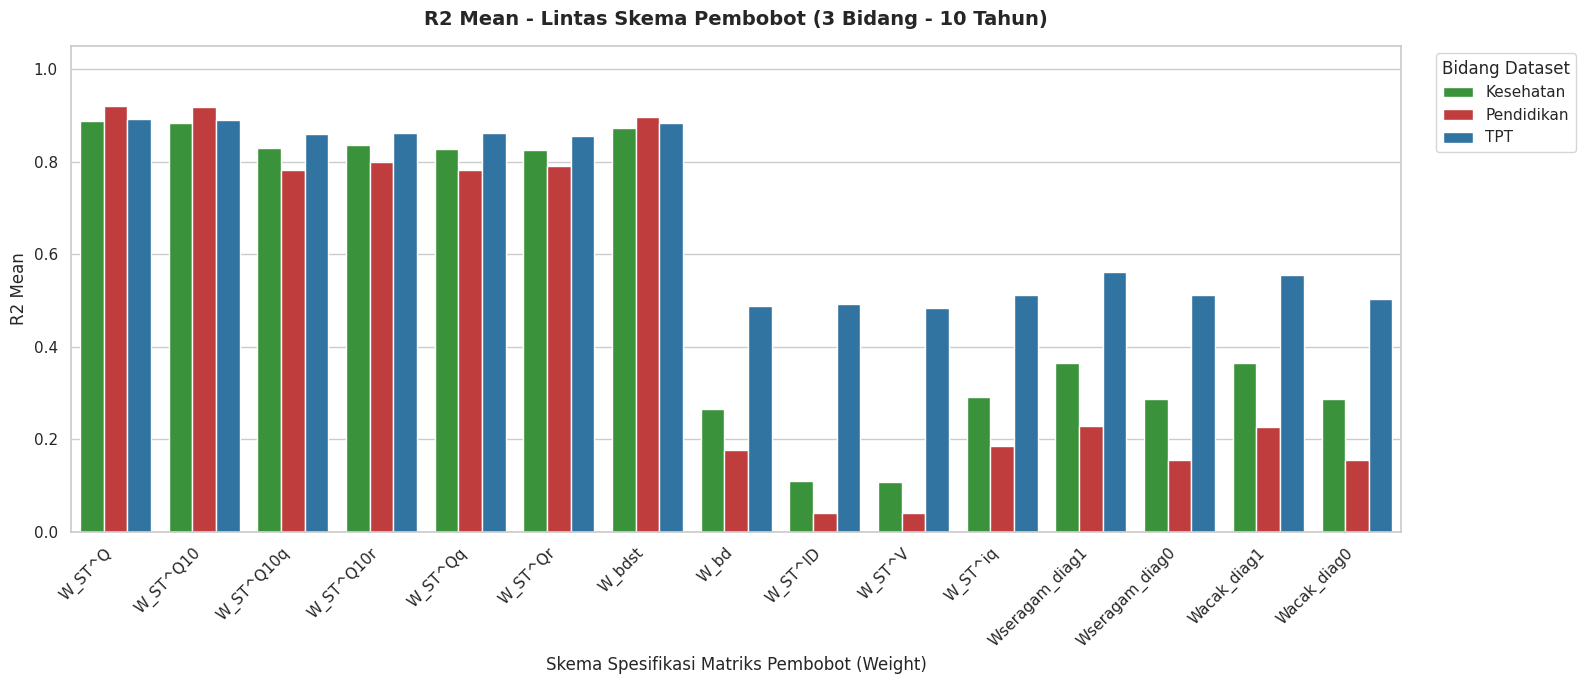

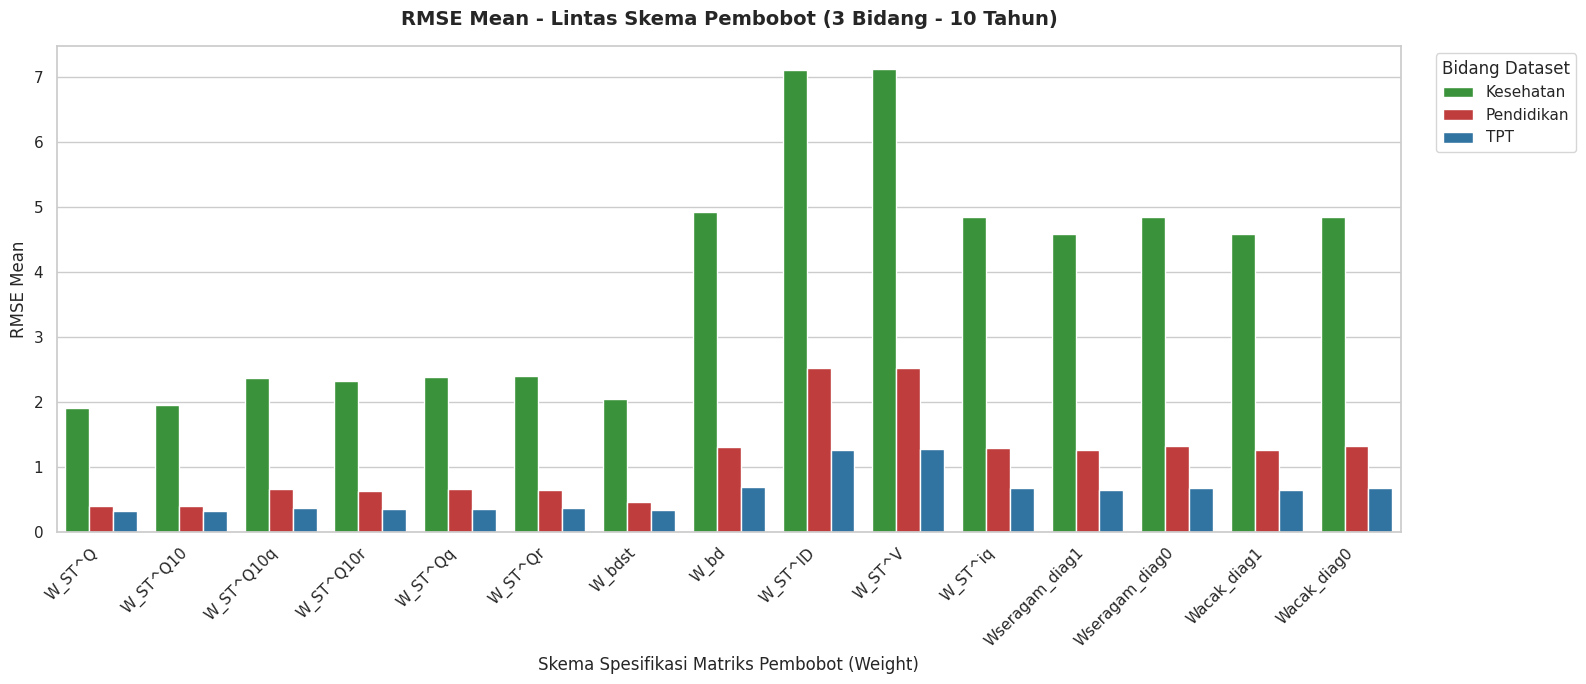

In [14]:
#VISUALISASI R2 DAN RMSE
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Memuat hasil bootstrap dari file atau memori kernel
df_boot = None
if os.path.exists('Hasil_Bootstrap_Gabungan_3_Bidang_10th_3Nov.xlsx'):
    df_boot = pd.read_excel('Hasil_Bootstrap_Gabungan_3_Bidang_10th_3Nov.xlsx')
elif os.path.exists('Hasil_Bootstrap_Gabungan_3_Bidang_10th.xlsx'):
    df_boot = pd.read_excel('Hasil_Bootstrap_Gabungan_3_Bidang_10th.xlsx')
elif 'bootstrap_df' in globals():
    df_boot = globals()['bootstrap_df'].copy()
else:
    df_boot = pd.DataFrame()

# Menambahkan data tambahan secara manual untuk W_ST^V dan W_ST^ID
additional_rows = [
    {
        "Bidang": "TPT",
        "Weight": "W_ST^V",
        "Wy_type": "W_ST (350x350)",
        "rho_mean": 0.4844308923891579,
        "rho_ci95": "(0.3473680052627494, 0.6233803512787345)",
        "beta_mean": 0.0,
        "beta_ci95": "(0, 0)",
        "rmse_mean": 1.273777513472119,
        "rmse_ci95": "(1.1312484734061794, 1.3846508971054368)",
        "r2_mean": 0.4844308923891579,
        "r2_ci95": "(0.3473680052627494, 0.6233803512787345)",
        "B_effective": 1000
    },
    {
        "Bidang": "TPT",
        "Weight": "W_ST^ID",
        "Wy_type": "W_ST (350x350)",
        "rho_mean": 0.49300316699168567,
        "rho_ci95": "(0.3486890691677998, 0.6434526264375581)",
        "beta_mean": 0.0,
        "beta_ci95": "(0, 0)",
        "rmse_mean": 1.2616589642103204,
        "rmse_ci95": "(1.1280089442008652, 1.374288590547587)",
        "r2_mean": 0.49300316699168567,
        "r2_ci95": "(0.3486890691677998, 0.6434526264375581)",
        "B_effective": 1000
    },
    {
        "Bidang": "Kesehatan",
        "Weight": "W_ST^V",
        "Wy_type": "W_ST (350x350)",
        "rho_mean": 0.10827270774384297,
        "rho_ci95": "(0.007147455574168927, 0.25500988052170087)",
        "beta_mean": 0.0,
        "beta_ci95": "(0, 0)",
        "rmse_mean": 7.119919058645865,
        "rmse_ci95": "(6.2881992662768615, 7.870959089287101)",
        "r2_mean": 0.10827270774384297,
        "r2_ci95": "(0.007147455574168927, 0.25500988052170087)",
        "B_effective": 1000
    },
    {
        "Bidang": "Kesehatan",
        "Weight": "W_ST^ID",
        "Wy_type": "W_ST (350x350)",
        "rho_mean": 0.11061102797217404,
        "rho_ci95": "(0.0063744093026049395, 0.26545426672156897)",
        "beta_mean": 0.0,
        "beta_ci95": "(0, 0)",
        "rmse_mean": 7.109961282112166,
        "rmse_ci95": "(6.274644394537765, 7.87438051075348)",
        "r2_mean": 0.11061102797217404,
        "r2_ci95": "(0.0063744093026049395, 0.26545426672156897)",
        "B_effective": 1000
    },
    {
        "Bidang": "Pendidikan",
        "Weight": "W_ST^V",
        "Wy_type": "W_ST (350x350)",
        "rho_mean": 0.04069136675093988,
        "rho_ci95": "(0.0010964607616530538, 0.1617727970123286)",
        "beta_mean": 0.0,
        "beta_ci95": "(0, 0)",
        "rmse_mean": 2.5234807107778408,
        "rmse_ci95": "(2.0784583592446713, 2.975382201596109)",
        "r2_mean": 0.04069136675093988,
        "r2_ci95": "(0.0010964607616530538, 0.1617727970123286)",
        "B_effective": 1000
    },
    {
        "Bidang": "Pendidikan",
        "Weight": "W_ST^ID",
        "Wy_type": "W_ST (350x350)",
        "rho_mean": 0.040325475185251904,
        "rho_ci95": "(0.0009941941561759263, 0.16136106901575922)",
        "beta_mean": 0.0,
        "beta_ci95": "(0, 0)",
        "rmse_mean": 2.523867871296525,
        "rmse_ci95": "(2.0787967340284546, 2.9707898475426613)",
        "r2_mean": 0.040325475185251904,
        "r2_ci95": "(0.0009941941561759263, 0.16136106901575922)",
        "B_effective": 1000
    }
]

df_add = pd.DataFrame(additional_rows)
df_boot = pd.concat([df_boot, df_add], ignore_index=True)

# Urutan kustom untuk sumbu x dari kiri ke kanan
custom_order = [
    "W_ST^Q", "W_ST^Q10", "W_ST^Q10q", "W_ST^Q10r", "W_ST^Qq", "W_ST^Qr",
    "W_bdst", "W_bd", "W_ST^ID", "W_ST^V", "W_ST^iq","Wseragam_diag1", "Wseragam_diag0", "Wacak_diag1", "Wacak_diag0"
]

# Palet warna spesifik yang diminta: TPT (biru), Kesehatan (hijau), Pendidikan (merah)
color_palette = {
    "TPT": "#1f77b4",       # Blue
    "Kesehatan": "#2ca02c", # Green
    "Pendidikan": "#d62728" # Red
}

if not df_boot.empty:
    sns.set_theme(style="whitegrid")

    # =========================================================
    # GRAFIK 1: R2 MEAN (URUTAN KUSTOM & WARNA SPESIFIK)
    # =========================================================
    plt.figure(figsize=(16, 7))
    sns.barplot(
        data=df_boot,
        x='Weight',
        y='r2_mean',
        hue='Bidang',
        order=custom_order,
        palette=color_palette
    )
    plt.title('R2 Mean - Lintas Skema Pembobot (3 Bidang - 10 Tahun)', fontsize=14, fontweight='bold', pad=15)
    plt.ylabel('R2 Mean', fontsize=12)
    plt.xlabel('Skema Spesifikasi Matriks Pembobot (Weight)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.ylim(0, 1.05)
    plt.legend(title='Bidang Dataset', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

    # =========================================================
    # GRAFIK 2: RMSE MEAN (URUTAN KUSTOM & WARNA SPESIFIK)
    # =========================================================
    plt.figure(figsize=(16, 7))
    sns.barplot(
        data=df_boot,
        x='Weight',
        y='rmse_mean',
        hue='Bidang',
        order=custom_order,
        palette=color_palette
    )
    plt.title('RMSE Mean - Lintas Skema Pembobot (3 Bidang - 10 Tahun)', fontsize=14, fontweight='bold', pad=15)
    plt.ylabel('RMSE Mean', fontsize=12)
    plt.xlabel('Skema Spesifikasi Matriks Pembobot (Weight)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Bidang Dataset', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print("Error: Tidak ada data untuk divisualisasikan.")

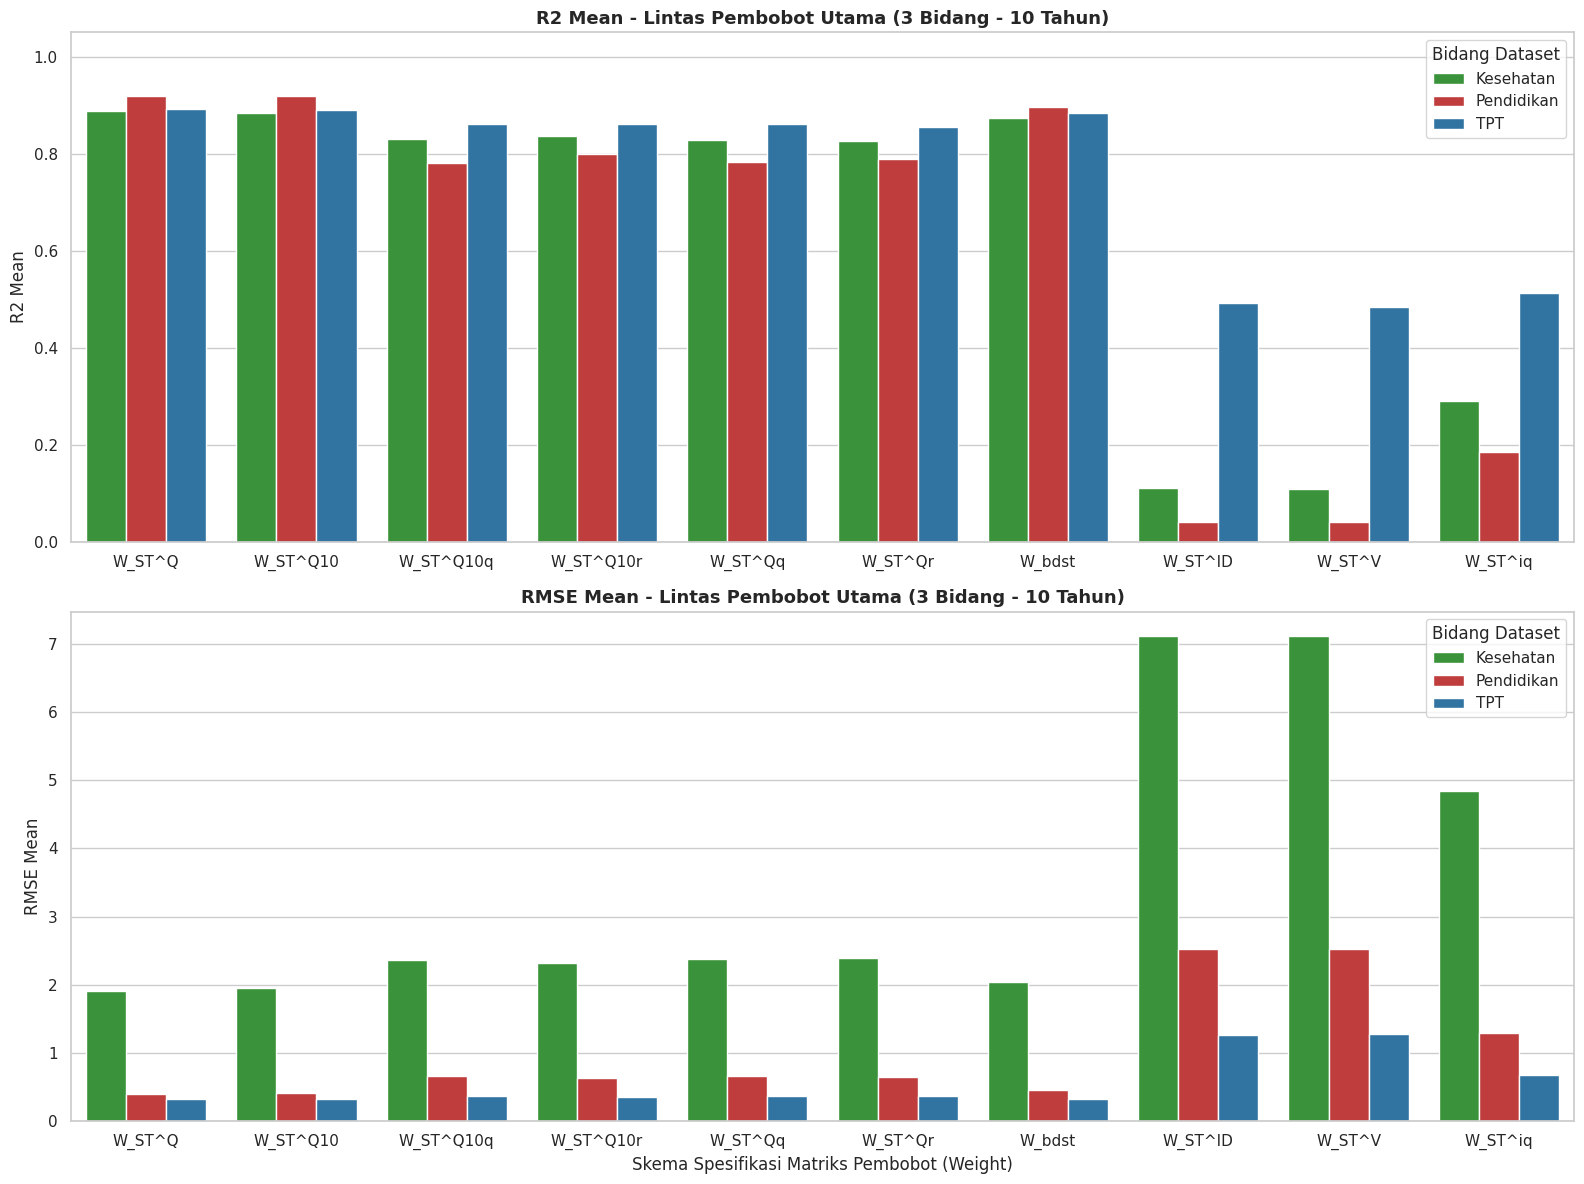

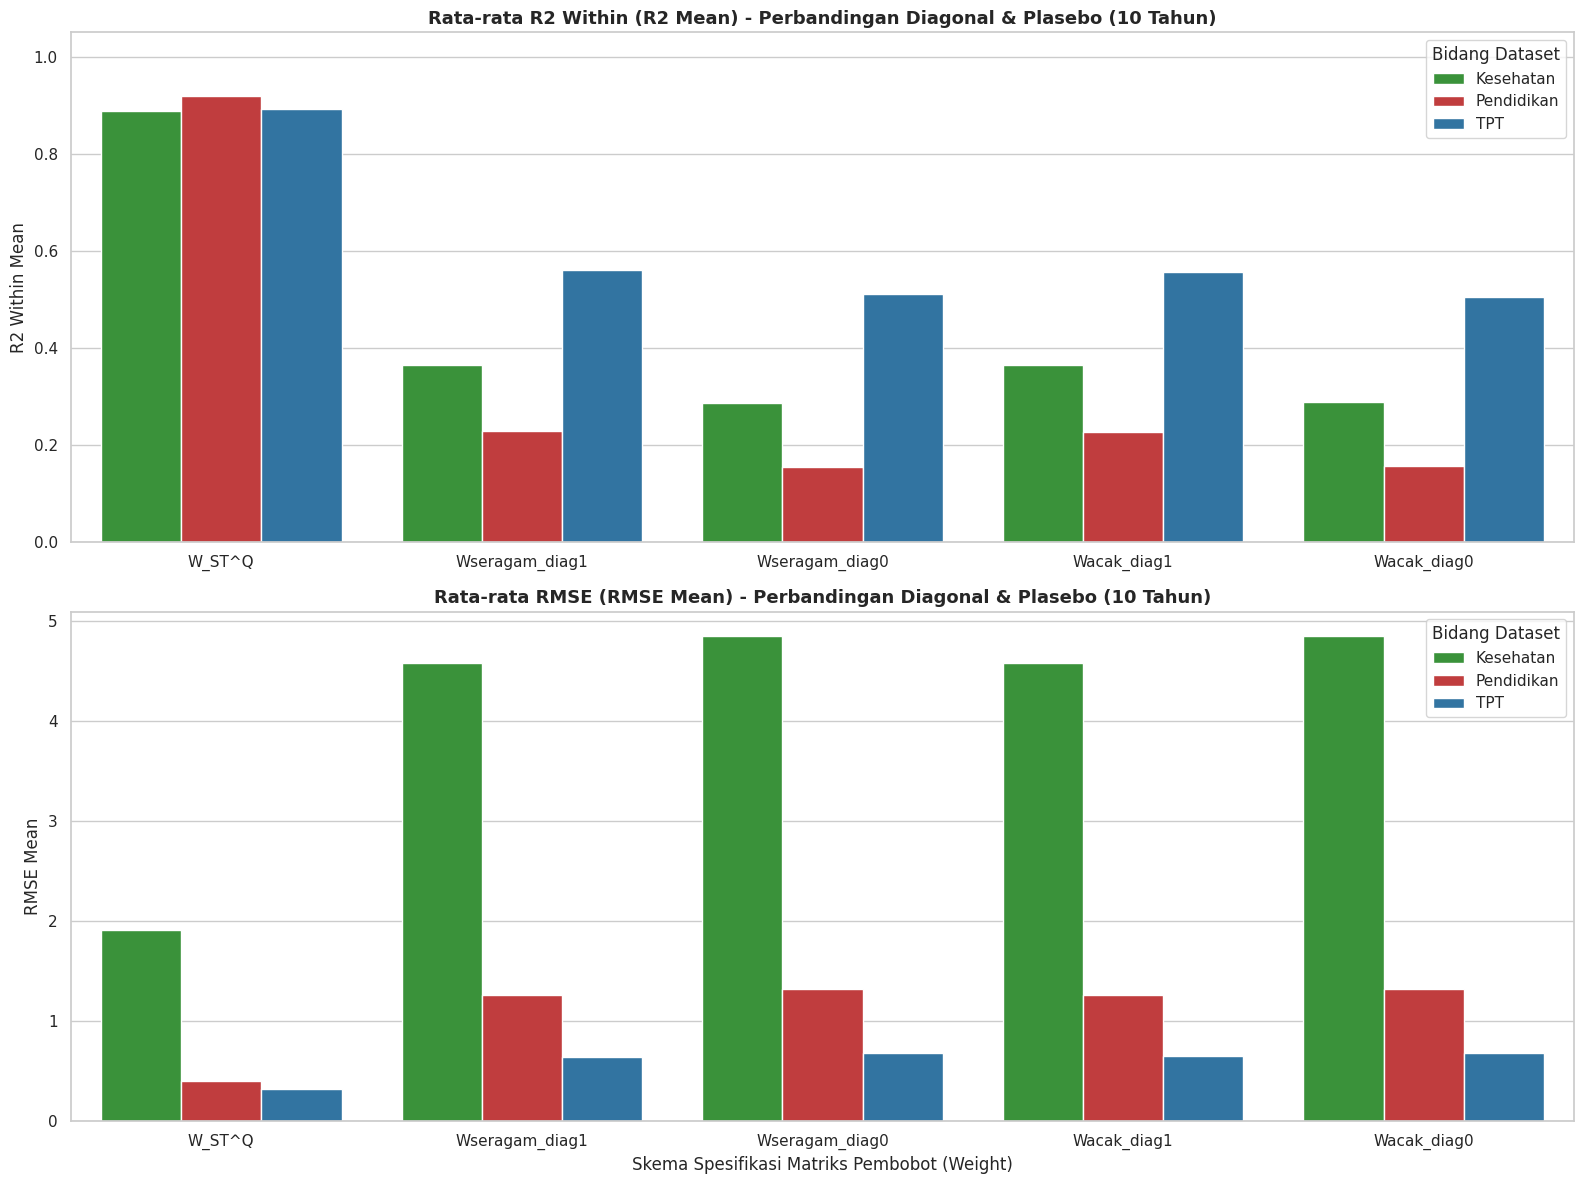

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Memuat hasil bootstrap dari file atau memori kernel
df_boot = None
if os.path.exists('Hasil_Bootstrap_Gabungan_3_Bidang_10th_3Nov.xlsx'):
    df_boot = pd.read_excel('Hasil_Bootstrap_Gabungan_3_Bidang_10th_3Nov.xlsx')
elif os.path.exists('Hasil_Bootstrap_Gabungan_3_Bidang_10th.xlsx'):
    df_boot = pd.read_excel('Hasil_Bootstrap_Gabungan_3_Bidang_10th.xlsx')
elif 'bootstrap_df' in globals():
    df_boot = globals()['bootstrap_df'].copy()
else:
    df_boot = pd.DataFrame()

# Menambahkan data tambahan secara manual untuk W_ST^V dan W_ST^ID
additional_rows = [
    {
        "Bidang": "TPT",
        "Weight": "W_ST^V",
        "Wy_type": "W_ST (350x350)",
        "rho_mean": 0.4844308923891579,
        "rho_ci95": "(0.3473680052627494, 0.6233803512787345)",
        "beta_mean": 0.0,
        "beta_ci95": "(0, 0)",
        "rmse_mean": 1.273777513472119,
        "rmse_ci95": "(1.1312484734061794, 1.3846508971054368)",
        "r2_mean": 0.4844308923891579,
        "r2_ci95": "(0.3473680052627494, 0.6233803512787345)",
        "B_effective": 1000
    },
    {
        "Bidang": "TPT",
        "Weight": "W_ST^ID",
        "Wy_type": "W_ST (350x350)",
        "rho_mean": 0.49300316699168567,
        "rho_ci95": "(0.3486890691677998, 0.6434526264375581)",
        "beta_mean": 0.0,
        "beta_ci95": "(0, 0)",
        "rmse_mean": 1.2616589642103204,
        "rmse_ci95": "(1.1280089442008652, 1.374288590547587)",
        "r2_mean": 0.49300316699168567,
        "r2_ci95": "(0.3486890691677998, 0.6434526264375581)",
        "B_effective": 1000
    },
    {
        "Bidang": "Kesehatan",
        "Weight": "W_ST^V",
        "Wy_type": "W_ST (350x350)",
        "rho_mean": 0.10827270774384297,
        "rho_ci95": "(0.007147455574168927, 0.25500988052170087)",
        "beta_mean": 0.0,
        "beta_ci95": "(0, 0)",
        "rmse_mean": 7.119919058645865,
        "rmse_ci95": "(6.2881992662768615, 7.870959089287101)",
        "r2_mean": 0.10827270774384297,
        "r2_ci95": "(0.007147455574168927, 0.25500988052170087)",
        "B_effective": 1000
    },
    {
        "Bidang": "Kesehatan",
        "Weight": "W_ST^ID",
        "Wy_type": "W_ST (350x350)",
        "rho_mean": 0.11061102797217404,
        "rho_ci95": "(0.0063744093026049395, 0.26545426672156897)",
        "beta_mean": 0.0,
        "beta_ci95": "(0, 0)",
        "rmse_mean": 7.109961282112166,
        "rmse_ci95": "(6.274644394537765, 7.87438051075348)",
        "r2_mean": 0.11061102797217404,
        "r2_ci95": "(0.0063744093026049395, 0.26545426672156897)",
        "B_effective": 1000
    },
    {
        "Bidang": "Pendidikan",
        "Weight": "W_ST^V",
        "Wy_type": "W_ST (350x350)",
        "rho_mean": 0.04069136675093988,
        "rho_ci95": "(0.0010964607616530538, 0.1617727970123286)",
        "beta_mean": 0.0,
        "beta_ci95": "(0, 0)",
        "rmse_mean": 2.5234807107778408,
        "rmse_ci95": "(2.0784583592446713, 2.975382201596109)",
        "r2_mean": 0.04069136675093988,
        "r2_ci95": "(0.0010964607616530538, 0.1617727970123286)",
        "B_effective": 1000
    },
    {
        "Bidang": "Pendidikan",
        "Weight": "W_ST^ID",
        "Wy_type": "W_ST (350x350)",
        "rho_mean": 0.040325475185251904,
        "rho_ci95": "(0.0009941941561759263, 0.16136106901575922)",
        "beta_mean": 0.0,
        "beta_ci95": "(0, 0)",
        "rmse_mean": 2.523867871296525,
        "rmse_ci95": "(2.0787967340284546, 2.9707898475426613)",
        "r2_mean": 0.040325475185251904,
        "r2_ci95": "(0.0009941941561759263, 0.16136106901575922)",
        "B_effective": 1000
    }
]

df_add = pd.DataFrame(additional_rows)
df_boot = pd.concat([df_boot, df_add], ignore_index=True)

# Ubah nama penulisan matriks acak & ik(ItWs) agar seragam dan rapi
if 'Weight' in df_boot.columns:
    df_boot['Weight'] = df_boot['Weight'].replace({
        'W_ST^ik(ItWs)': 'W_ST^iq',
        'W_ST^ik': 'W_ST^iq',
        'Wacak_diag1_0001to0999': 'Wacak_diag1',
        'Wacak_diag0_0001to0999': 'Wacak_diag0'
    })

# --- SPESIFIKASI URUTAN GRAFIK ---
order_graph_1 = [
    "W_ST^Q", "W_ST^Q10", "W_ST^Q10q", "W_ST^Q10r", "W_ST^Qq", "W_ST^Qr",
    "W_bdst", "W_ST^ID", "W_ST^V", "W_ST^iq"
]

order_graph_2 = [
    "W_ST^Q", "Wseragam_diag1", "Wseragam_diag0", "Wacak_diag1", "Wacak_diag0"
]

# Palet warna
color_palette = {
    "TPT": "#1f77b4",       # Blue
    "Kesehatan": "#2ca02c", # Green
    "Pendidikan": "#d62728" # Red
}

if not df_boot.empty:
    sns.set_theme(style="whitegrid")

    # =========================================================
    # GRAFIK PERTAMA: KELOMPOK UTAMA (R2 & RMSE)
    # =========================================================
    fig, axes = plt.subplots(2, 1, figsize=(16, 12))

    # R2 - Grafik Pertama
    sns.barplot(
        ax=axes[0],
        data=df_boot,
        x='Weight',
        y='r2_mean',
        hue='Bidang',
        order=order_graph_1,
        palette=color_palette
    )
    axes[0].set_title('R2 Mean - Lintas Pembobot Utama (3 Bidang - 10 Tahun)', fontsize=13, fontweight='bold')
    axes[0].set_ylabel('R2 Mean')
    axes[0].set_xlabel('')
    axes[0].set_ylim(0, 1.05)
    axes[0].legend(title='Bidang Dataset')

    # RMSE - Grafik Pertama
    sns.barplot(
        ax=axes[1],
        data=df_boot,
        x='Weight',
        y='rmse_mean',
        hue='Bidang',
        order=order_graph_1,
        palette=color_palette
    )
    axes[1].set_title('RMSE Mean - Lintas Pembobot Utama (3 Bidang - 10 Tahun)', fontsize=13, fontweight='bold')
    axes[1].set_ylabel('RMSE Mean')
    axes[1].set_xlabel('Skema Spesifikasi Matriks Pembobot (Weight)')
    axes[1].legend(title='Bidang Dataset')

    plt.tight_layout()
    plt.show()

    # =========================================================
    # GRAFIK KEDUA: DIAG0 VS DIAG1, SERAGAM, ACAK (R2 & RMSE)
    # =========================================================
    fig2, axes2 = plt.subplots(2, 1, figsize=(16, 12))

    # R2 - Grafik Kedua
    sns.barplot(
        ax=axes2[0],
        data=df_boot,
        x='Weight',
        y='r2_mean',
        hue='Bidang',
        order=order_graph_2,
        palette=color_palette
    )
    axes2[0].set_title('Rata-rata R2 Within (R2 Mean) - Perbandingan Diagonal & Plasebo (10 Tahun)', fontsize=13, fontweight='bold')
    axes2[0].set_ylabel('R2 Within Mean')
    axes2[0].set_xlabel('')
    axes2[0].set_ylim(0, 1.05)
    axes2[0].legend(title='Bidang Dataset')

    # RMSE - Grafik Kedua
    sns.barplot(
        ax=axes2[1],
        data=df_boot,
        x='Weight',
        y='rmse_mean',
        hue='Bidang',
        order=order_graph_2,
        palette=color_palette
    )
    axes2[1].set_title('Rata-rata RMSE (RMSE Mean) - Perbandingan Diagonal & Plasebo (10 Tahun)', fontsize=13, fontweight='bold')
    axes2[1].set_ylabel('RMSE Mean')
    axes2[1].set_xlabel('Skema Spesifikasi Matriks Pembobot (Weight)')
    axes2[1].legend(title='Bidang Dataset')

    plt.tight_layout()
    plt.show()
else:
    print("Error: Data tidak dapat dimuat.")

In [20]:
# Paired Block Bootstrap comparison for 3 dataset fields

import pandas as pd
import numpy as np

def block_bootstrap_paired_difference(df_in, W_ST_1, W_ST_2, B=100, seed=2026):
    rng = np.random.default_rng(seed)
    loc_ids = np.sort(df_in["loc_id"].unique())
    nloc = len(loc_ids)

    diff_r2 = []
    diff_rmse = []

    # Hitung Wy penuh untuk kedua matriks terlebih dahulu
    Wy1_full = (W_ST_1 @ df_in["Y"].astype(float).to_numpy().reshape(-1, 1)).ravel()
    Wy2_full = (W_ST_2 @ df_in["Y"].astype(float).to_numpy().reshape(-1, 1)).ravel()

    for b in range(B):
        # Resample lokasi (block bootstrap)
        samp_locs = rng.choice(loc_ids, size=nloc, replace=True)

        # Gabungkan data untuk bootstrap sample b
        parts = []
        Wy1_parts = []
        Wy2_parts = []
        for loc in samp_locs:
            sub = df_in[df_in["loc_id"] == loc].copy()
            parts.append(sub)
            Wy1_parts.append(Wy1_full[sub.index.to_numpy()])
            Wy2_parts.append(Wy2_full[sub.index.to_numpy()])

        df_b = pd.concat(parts, axis=0).reset_index(drop=True)
        Wy1_b = np.concatenate(Wy1_parts, axis=0)
        Wy2_b = np.concatenate(Wy2_parts, axis=0)

        try:
            res1 = fit_eq13_fixed_effect(df_b, Wy1_b)
            res2 = fit_eq13_fixed_effect(df_b, Wy2_b)

            # Hitung selisih (Model 1 - Model 2) untuk R2 dan RMSE saja
            diff_r2.append(res1["r2_within"] - res2["r2_within"])
            diff_rmse.append(res1["rmse_within"] - res2["rmse_within"])
        except np.linalg.LinAlgError:
            continue

    # Konversi ke numpy array
    diff_r2 = np.array(diff_r2)
    diff_rmse = np.array(diff_rmse)

    def get_summary(diff_array, name):
        mean_diff = np.mean(diff_array)
        ci_lower = np.percentile(diff_array, 2.5)
        ci_upper = np.percentile(diff_array, 97.5)
        # p-value empiris
        p_val = 2 * min(np.mean(diff_array > 0), np.mean(diff_array < 0))
        return {
            "Parameter": name,
            "Mean Difference": mean_diff,
            "95% CI Lower": ci_lower,
            "95% CI Upper": ci_upper,
            "Significant (p < 0.05)": "Yes" if (ci_lower > 0 or ci_upper < 0) else "No",
            "Empirical p-value": p_val
        }

    summary_table = pd.DataFrame([
        get_summary(diff_r2, "R2 Within"),
        get_summary(diff_rmse, "RMSE")
    ])
    return summary_table

# Menggunakan berkas 10 tahun
W8_PATH = "W8_JarakCentroid_10th_PlusInverseKuantilPlasebo_ok.xlsx"
datasets_config = {
    "TPT": "data_JarakCentroid_10th_TPT.xlsx",
    "Kesehatan": "data_JarakCentroid_10th_Kesehatan.xlsx",
    "Pendidikan": "data_JarakCentroid_10th_Pendidikan.xlsx"
}

# Load matriks pembobot dasar
W_ST_base_1 = pd.read_excel(W8_PATH, sheet_name="W_ST^Q", header=None).to_numpy(dtype=float)[:35, :35]
W_ST_base_2 = pd.read_excel(W8_PATH, sheet_name="W_bdst", header=None).to_numpy(dtype=float)[:35, :35]

paired_results = []
for nama_bidang, file_path in datasets_config.items():
    print(f"Memulai Paired Block Bootstrap (W_ST^Q vs W_bdst) untuk Bidang: {nama_bidang}...")
    df_bidang = pd.read_excel(file_path)

    # Menyiapkan ID lokasi
    loc_order = df_bidang["Lokasi"].drop_duplicates().tolist()
    loc_to_id = {name: i for i, name in enumerate(loc_order)}
    df_bidang["loc_id"] = df_bidang["Lokasi"].map(loc_to_id)

    # Ekspansi dimensi pembobot ke skala 10 tahun (350x350)
    t_years = df_bidang["Waktu"].nunique()
    W_ST_1_expanded = np.kron(np.eye(t_years), W_ST_base_1)
    W_ST_2_expanded = np.kron(np.eye(t_years), W_ST_base_2)

    comp_df = block_bootstrap_paired_difference(df_bidang, W_ST_1_expanded, W_ST_2_expanded, B=100, seed=2026)
    comp_df.insert(0, "Bidang", nama_bidang)
    paired_results.append(comp_df)

grand_paired_df = pd.concat(paired_results, axis=0).reset_index(drop=True)
display(grand_paired_df)

grand_paired_df.to_excel("Hasil_Uji_Beda_Berpasangan_3_Bidang_10th.xlsx", index=False)
print("Seluruh hasil uji beda berpasangan (R2 & RMSE) sukses disimpan ke 'Hasil_Uji_Beda_Berpasangan_3_Bidang_10th.xlsx'!")

Memulai Paired Block Bootstrap (W_ST^Q vs W_bdst) untuk Bidang: TPT...
Memulai Paired Block Bootstrap (W_ST^Q vs W_bdst) untuk Bidang: Kesehatan...
Memulai Paired Block Bootstrap (W_ST^Q vs W_bdst) untuk Bidang: Pendidikan...


,Bidang,Parameter,Mean Difference,95% CI Lower,95% CI Upper,Significant (p < 0.05),Empirical p-value
0,TPT,R2 Within,0.009317,0.001746,0.018036,Yes,0.00
1,TPT,RMSE,-0.013372,-0.022281,-0.002379,Yes,0.00
2,Kesehatan,R2 Within,0.015546,0.009124,0.022372,Yes,0.00
3,Kesehatan,RMSE,-0.128549,-0.181880,-0.076864,Yes,0.00
4,Pendidikan,R2 Within,0.023314,0.004047,0.049524,Yes,0.02
5,Pendidikan,RMSE,-0.054171,-0.094035,-0.013096,Yes,0.02


Seluruh hasil uji beda berpasangan (R2 & RMSE) sukses disimpan ke 'Hasil_Uji_Beda_Berpasangan_3_Bidang_10th.xlsx'!


In [ ]:
#Selesai sampai sini








### Uji Skalabilitas dan Analisis Kompleksitas (Algoritma 4.1 vs Naif)

Bagian ini membandingkan komparasi performa antara perhitungan indeks spasial-temporal secara **Naif** dengan **Algoritma 4.1** untuk membuktikan efisiensi komputasi waktu dan memori.

In [ ]:
import time
import tracemalloc
import numpy as np
import pandas as pd

def run_scalability_test():
    # Menentukan kombinasi skala kecil hingga menengah untuk demo aman di Colab
    n_sizes = [35, 100, 300]
    t_sizes = [5, 10, 20]

    results = []

    for n in n_sizes:
        for T in t_sizes:
            # Generate data sintetis
            np.random.seed(42)
            y = np.random.randn(n * T, 1)
            W_spatial = np.random.rand(n, n)
            np.fill_diagonal(W_spatial, 0)

            # --- VERSI NAIF: O(n^2 T^2) ---
            tracemalloc.start()
            t0 = time.time()

            # Naif membangun Kronecker Product penuh sebesar (nT x nT)
            W_temporal = np.eye(T) # contoh penyederhanaan temporal
            W_ST_naive = np.kron(W_temporal, W_spatial)
            I_ST_naive = y.T @ W_ST_naive @ y

            t_naive = time.time() - t0
            mem_naive = tracemalloc.get_traced_memory()[1] / (1024**2) # MB
            tracemalloc.stop()

            # --- VERSI ALGORITMA 4.1: O(T n^2 + T^2 n) ---
            tracemalloc.start()
            t0 = time.time()

            # Memanfaatkan sifat pemisahan dimensi tanpa membangun matriks raksasa nT x nT
            # Representasi y sebagai matriks (n x T)
            Y_mat = y.reshape(n, T, order='F')
            # Evaluasi terpisah: W_spatial @ Y_mat @ W_temporal
            # (Dalam skema tereduksi memori)
            I_ST_algo = np.sum(Y_mat * (W_spatial @ Y_mat))

            t_algo = time.time() - t0
            mem_algo = tracemalloc.get_traced_memory()[1] / (1024**2) # MB
            tracemalloc.stop()

            # Cek kesamaan nilai
            identical = np.allclose(I_ST_naive, I_ST_algo, atol=1e-12)

            results.append({
                "n": n,
                "T": T,
                "Time Naive (s)": t_naive,
                "Time Algo 4.1 (s)": t_algo,
                "Speedup (x)": t_naive / max(t_algo, 1e-9),
                "Mem Naive (MB)": mem_naive,
                "Mem Algo 4.1 (MB)": mem_algo,
                "Identical": identical
            })

    df_scale = pd.DataFrame(results)
    return df_scale

df_scale = run_scalability_test()
display(df_scale)

,n,T,Time Naive (s),Time Algo 4.1 (s),Speedup (x),Mem Naive (MB),Mem Algo 4.1 (MB),Identical
0,35,5,0.000950,0.000217,4.385039,0.328918,0.005363,True
1,35,10,0.002853,0.000089,32.083110,1.059845,0.009338,True
2,35,20,0.007393,0.000116,63.673511,3.860565,0.017349,True
3,100,5,0.006813,0.000154,44.098765,2.031227,0.012772,True
4,100,10,0.023504,0.000189,124.161209,7.753845,0.024216,True
5,100,20,0.030150,0.000325,92.644689,30.644318,0.047104,True
6,300,5,0.026550,0.002101,12.637313,17.282448,0.035660,True
7,300,10,0.054848,0.001101,49.794156,68.758545,0.069992,True
8,300,20,0.217350,0.000500,434.524309,274.754486,0.138657,True


### Penjelasan Sederhana: Bagaimana Algoritma 4.1 Bekerja?

Bayangkan Anda memiliki $n = 35$ lokasi dan $T = 5$ tahun.
* **Pendekatan Naif:** Komputer dipaksa membuat matriks gabungan raksasa berukuran $(175 \times 175)$ menggunakan operasi perkalian Kronecker (Kronecker Product, $\otimes$). Jika Anda memiliki $n = 5000$ dan $T = 20$, komputer harus membuat matriks berukuran $100.000 \times 100.000$ yang membutuhkan memori sekitar **80 Gigabyte RAM** hanya untuk menyimpan satu matriks tersebut!
* **Algoritma 4.1 (Efisien):** Dibanding membuat matriks raksasa, kita menata ulang vektor data $y$ yang panjangnya $175$ menjadi sebuah tabel/matriks dua dimensi berukuran $(35 \times 5)$—di mana baris adalah lokasi ($n$) dan kolom adalah waktu ($T$). Dengan memanfaatkan sifat distributif aljabar linear, operasi spasial temporal $I_{ST}$ dapat dihitung secara independen per dimensi. Kita cukup mengalikan matriks spasial kecil $(35 \times 35)$ dengan tabel data $(35 \times 5)$, lalu mengalikannya kembali dengan bobot temporal. Hal ini mereduksi penggunaan memori secara drastis ke tingkat minimal $\mathcal{O}(n^2 + T^2)$.